# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
import os
import string
import re
import ast 

import networkx as nx
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import mlflow
import pandas as pd
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize


from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)
from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
runs_to_download = []

runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and attributes.run_name = 'HybridModel' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))

5


In [3]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-09-23 16:21:17,274 - INFO - Downloading artifacts for run 4ce2c0cbe5454315b45fb0277d11fd12
2026-09-23 16:21:24,079 - INFO - Downloading artifacts for run 1cd5efb3ef374f51ad9a5ced5e80d541
2026-09-23 16:21:26,386 - INFO - Downloading artifacts for run 5922b969bd6942d0bf5e7bf6901952e9
2026-09-23 16:21:28,617 - INFO - Downloading artifacts for run e6f120fab5b24d2ba199a4a7fa78ec25
2026-09-23 16:21:30,807 - INFO - Downloading artifacts for run c24b7e48838c4020830d1f4bd8cd5232


,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b


In [4]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None),
        })
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
1,1cd5efb3ef374f51ad9a5ced5e80d541,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
2,5922b969bd6942d0bf5e7bf6901952e9,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod..."
3,e6f120fab5b24d2ba199a4a7fa78ec25,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
4,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."


In [5]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add noiseless expression values

In [6]:
assert raw_predictions_df['parent_run_id'].nunique() == 1

In [7]:
run_id = raw_predictions_df['parent_run_id'].unique()[0]
ml_flow_download_path = mlflow.artifacts.download_artifacts(
    run_id=run_id, artifact_path="dataset"
)
sim_output = SimulationResult.load_from_pkl(
    Path(ml_flow_download_path) / "simulation_result.pkl"
)
sim_output.noiseless_for_testing = True
long_form_simulation = sim_output.to_long_form_df()
long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id


2026-09-23 16:21:40,223 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,330 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,453 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,524 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,622 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,739 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,848 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-23 16:21:40,936 - WARNING - Connection p

In [8]:
per_model_graph_characteristics = []
for modelled_genes in model_name_df['modelled_genes'].unique():
    # Convert back into list
    modelled_genes_list = ast.literal_eval(modelled_genes)
    graph = sim_output.network._graph
    # Get the density, size, conductance?
    per_model_graph_characteristics.append({
        'modelled_genes': modelled_genes,
        'nr_nodes_in_mm': len(modelled_genes_list),
        'nr_edges_in_mm': graph.subgraph(modelled_genes_list).number_of_edges(),
        'conductance': nx.conductance(graph, modelled_genes_list),
        'density': nx.density(graph.subgraph(modelled_genes_list)),
    })
graph_characteristics_df = pd.DataFrame(per_model_graph_characteristics)
graph_characteristics_df

,modelled_genes,nr_nodes_in_mm,nr_edges_in_mm,conductance,density
0,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",13,39,0.204545,0.250000
1,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",8,9,0.416667,0.160714
2,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242
3,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",7,10,0.500000,0.238095
4,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",8,33,0.171429,0.589286


In [9]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."


In [10]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b


Merging

In [11]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

In [12]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,f02bf732b2ba4817b254bd5174f1549b
...,...,...,...,...,...,...,...,...,...,...,...
524995,Node_45,1.0,1.045748,1.065557,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",1.087935,f02bf732b2ba4817b254bd5174f1549b
524996,Node_46,1.0,0.359641,0.438852,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.446002,f02bf732b2ba4817b254bd5174f1549b
524997,Node_47,1.0,0.187503,0.054999,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.104842,f02bf732b2ba4817b254bd5174f1549b
524998,Node_48,1.0,0.975846,0.985961,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.902062,f02bf732b2ba4817b254bd5174f1549b


<Axes: xlabel='ground_truth_from_simulation', ylabel='ground_truth_from_pred_df'>

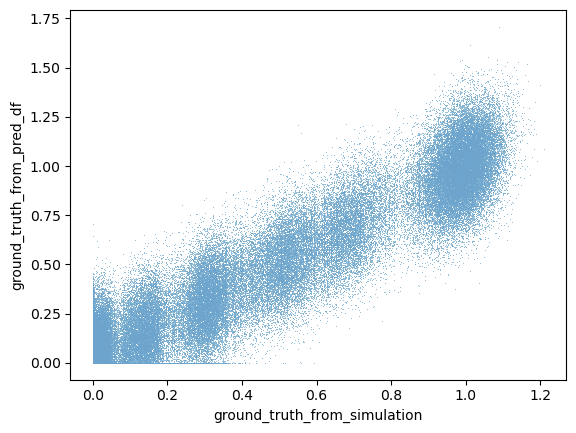

In [13]:
sns.scatterplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', s=2, alpha=.2, marker='.')

In [14]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth
0,Node_0,0.0,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225
1,Node_1,0.0,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310
2,Node_2,0.0,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057
3,Node_3,0.0,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816
4,Node_4,0.0,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769
...,...,...,...,...,...,...,...,...
524995,Node_45,1.0,1.045748,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",1.087935
524996,Node_46,1.0,0.359641,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.446002
524997,Node_47,1.0,0.187503,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.104842
524998,Node_48,1.0,0.975846,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.902062


In [15]:
outcome = outcome.merge(graph_characteristics_df, on='modelled_genes')

In [16]:
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_nodes_in_mm,nr_edges_in_mm,conductance,density
0,Node_0,0.0,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,13,39,0.204545,0.250000
1,Node_1,0.0,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,13,39,0.204545,0.250000
2,Node_2,0.0,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,13,39,0.204545,0.250000
3,Node_3,0.0,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,13,39,0.204545,0.250000
4,Node_4,0.0,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,13,39,0.204545,0.250000
...,...,...,...,...,...,...,...,...,...,...,...,...
524995,Node_45,1.0,1.045748,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",1.087935,8,33,0.171429,0.589286
524996,Node_46,1.0,0.359641,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.446002,8,33,0.171429,0.589286
524997,Node_47,1.0,0.187503,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.104842,8,33,0.171429,0.589286
524998,Node_48,1.0,0.975846,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.902062,8,33,0.171429,0.589286


In [17]:
genes_to_letter_map = {}
i = 0
for genes in natsorted(outcome['modelled_genes'].unique()):
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
    i += 1
genes_to_letter_map

{"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'A',
 "['Node_9', 'Node_18', 'Node_14', 'Node_21', 'Node_36', 'Node_40', 'Node_41']": 'B',
 "['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'C',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'D',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'E'}

In [18]:
outcome['model_name_long'] = outcome['model_name'] + ' ' + outcome['modelled_genes'].map(genes_to_letter_map).fillna('')
outcome['model_name_long'].nunique()

5

In [19]:
outcome['model_name_long'].unique().tolist()

['HybridModel C',
 'HybridModel E',
 'HybridModel A',
 'HybridModel B',
 'HybridModel D']

In [20]:
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_nodes_in_mm,nr_edges_in_mm,conductance,density,model_name_long
0,Node_0,0.0,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,13,39,0.204545,0.250000,HybridModel C
1,Node_1,0.0,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,13,39,0.204545,0.250000,HybridModel C
2,Node_2,0.0,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,13,39,0.204545,0.250000,HybridModel C
3,Node_3,0.0,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,13,39,0.204545,0.250000,HybridModel C
4,Node_4,0.0,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,13,39,0.204545,0.250000,HybridModel C
...,...,...,...,...,...,...,...,...,...,...,...,...,...
524995,Node_45,1.0,1.045748,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",1.087935,8,33,0.171429,0.589286,HybridModel D
524996,Node_46,1.0,0.359641,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.446002,8,33,0.171429,0.589286,HybridModel D
524997,Node_47,1.0,0.187503,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.104842,8,33,0.171429,0.589286,HybridModel D
524998,Node_48,1.0,0.975846,KO: Node_15. Env: None,c24b7e48838c4020830d1f4bd8cd5232,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",0.902062,8,33,0.171429,0.589286,HybridModel D


In [21]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [22]:
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [23]:
double_ko_df = annotate_kos_in_df(double_ko_df)

In [26]:
groupby_list = [
    'model_name_long', # Or model_name below depending on what plot you want to make
    # 'model_name',
    'modelled_genes',
    'nr_nodes_in_mm',
    'nr_edges_in_mm',
    'conductance',
    'density',
    'gene_in_mm',
    'ko_in_mm',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)


mse_df_long_model_name

,model_name_long,modelled_genes,nr_nodes_in_mm,nr_edges_in_mm,conductance,density,gene_in_mm,ko_in_mm,gene,condition,MSE
0,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242,False,fully,Node_0,"KO: Node_12, Node_23. Env: None",0.015879
1,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242,False,fully,Node_0,"KO: Node_2, Node_12. Env: None",0.053743
2,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242,False,fully,Node_0,"KO: Node_2, Node_17. Env: None",0.028576
3,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242,False,fully,Node_0,"KO: Node_2, Node_23. Env: None",0.040798
4,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",14,47,0.117647,0.258242,False,fully,Node_0,"KO: Node_2, Node_3. Env: None",0.028538
...,...,...,...,...,...,...,...,...,...,...,...
12495,HybridModel E,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",8,9,0.416667,0.160714,True,partially,Node_33,"KO: Node_8, Node_10. Env: None",0.005858
12496,HybridModel E,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",8,9,0.416667,0.160714,True,partially,Node_39,"KO: Node_1, Node_10. Env: None",0.003226
12497,HybridModel E,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",8,9,0.416667,0.160714,True,partially,Node_39,"KO: Node_8, Node_10. Env: None",0.003073
12498,HybridModel E,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",8,9,0.416667,0.160714,True,partially,Node_49,"KO: Node_1, Node_10. Env: None",0.002613


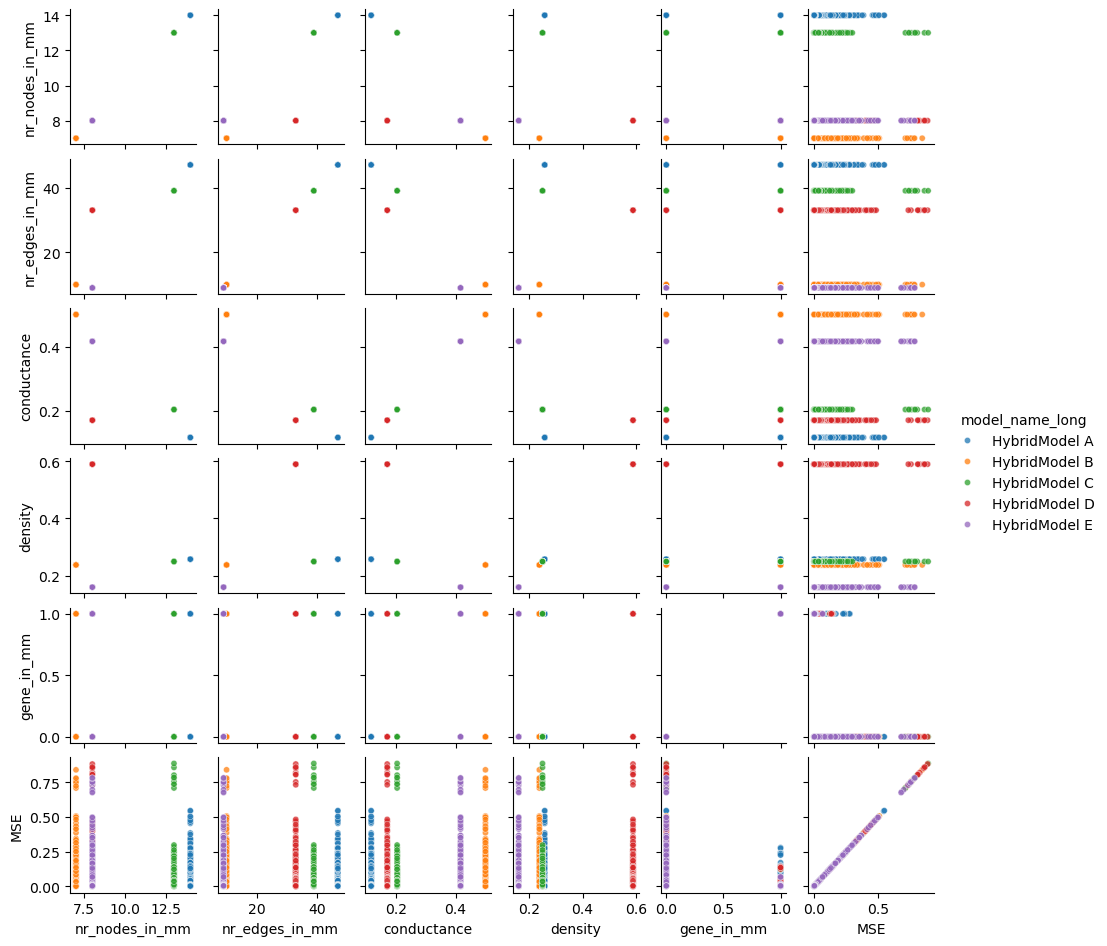

In [27]:
g = sns.pairplot(mse_df_long_model_name, hue='model_name_long', plot_kws={'alpha': .75, 's': 20}, diag_kind=None, height=1.6, aspect=1)
for ax in g.axes.flat:
    for collection in ax.collections:
        collection.set_rasterized(True)
# g.savefig("comparing_mm_pairplot.pdf", dpi=600, bbox_inches='tight')

For comment: See how the MSE compares for the different MM genes and KOs.

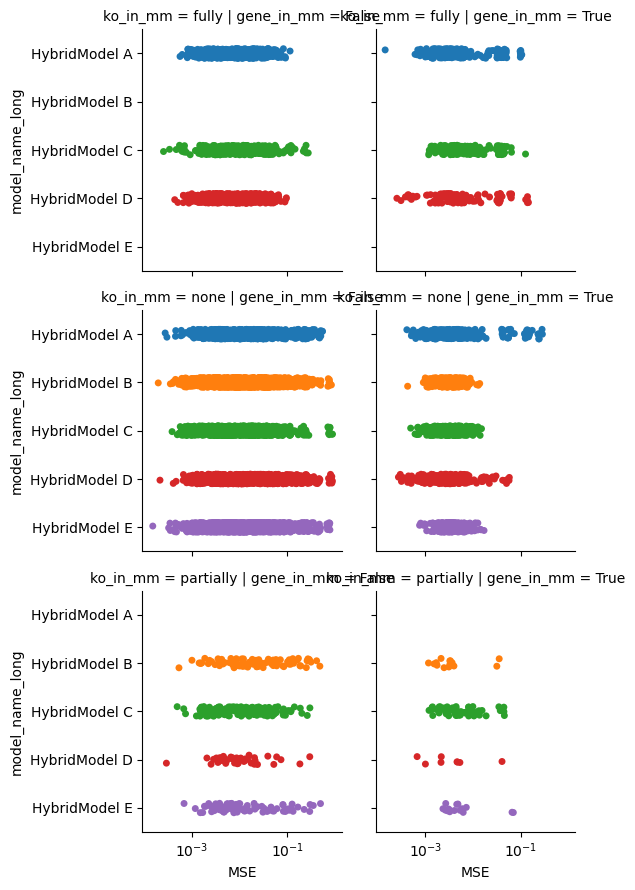

In [ ]:
# FILL IN HERE

g = sns.catplot(mse_df_long_model_name, col='gene_in_mm', row='ko_in_mm', y='model_name_long', hue='model_name_long', x='MSE', height=3, aspect=1, kind='strip', log_scale=True)
for ax in g.axes.flat:
    for collection in ax.collections:
        collection.set_rasterized(True)
# g.savefig("comparing_mm_pairplot.pdf", dpi=600, bbox_inches='tight')

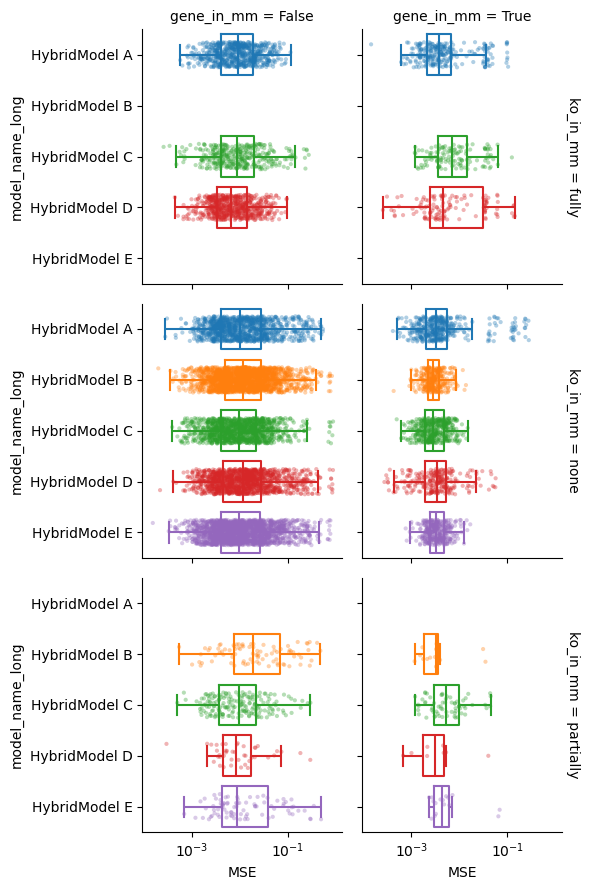

In [47]:
order = sorted(mse_df_long_model_name['model_name_long'].unique())
palette = dict(zip(order, sns.color_palette(n_colors=len(order))))

g = sns.catplot(
    data=mse_df_long_model_name,
    col='gene_in_mm', row='ko_in_mm',
    x='MSE', y='model_name_long', hue='model_name_long',
    order=order, hue_order=order, palette=palette,
    kind='box', log_scale=True,
    fill=False,          # outline boxes so the points stay visible
    showfliers=False,    # the strip already shows every point, outliers included
    height=3, aspect=1, legend=False,  margin_titles=True
)

g.map_dataframe(
    sns.stripplot,
    x='MSE', y='model_name_long', hue='model_name_long',
    order=order, hue_order=order, palette=palette,
    alpha=0.35, size=3, jitter=0.25, linewidth=0, legend=False,
)

# Only the strip points are PathCollections, so this rasterises the points
# and leaves the boxes as crisp vector graphics in the PDF
for ax in g.axes.flat:
    for collection in ax.collections:
        collection.set_rasterized(True)
g.savefig("comparing_mm_pairplot_split_by_gene_ko.pdf", dpi=600, bbox_inches='tight')

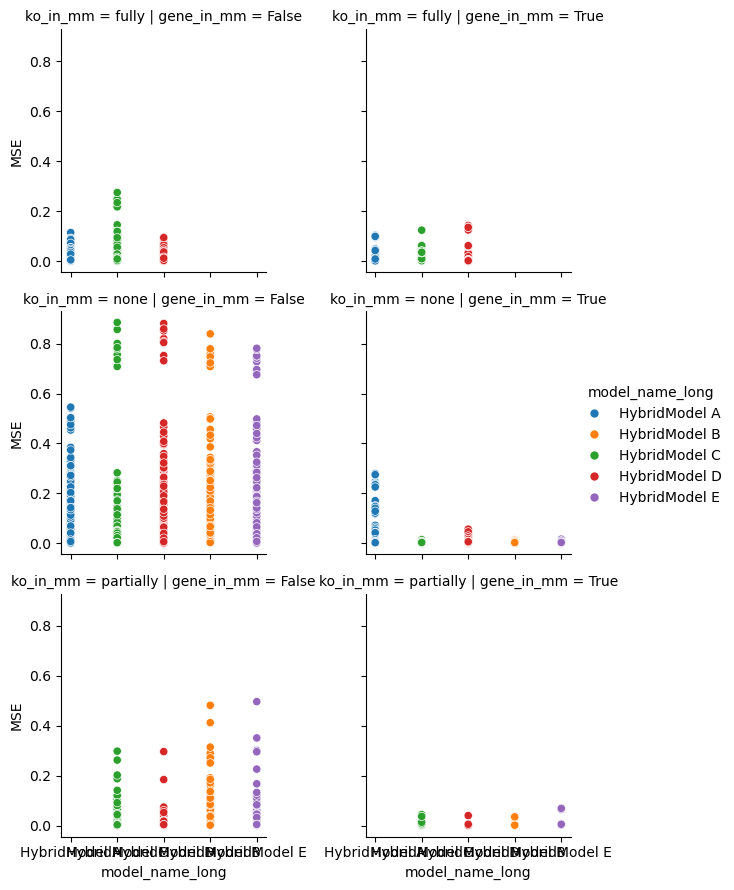

In [34]:
# FILL IN HERE
g = sns.relplot(mse_df_long_model_name, col='gene_in_mm', row='ko_in_mm', x='model_name_long', hue='model_name_long', y='MSE', height=3, aspect=1)
for ax in g.axes.flat:
    for collection in ax.collections:
        collection.set_rasterized(True)
# g.savefig("comparing_mm_pairplot.pdf", dpi=600, bbox_inches='tight')

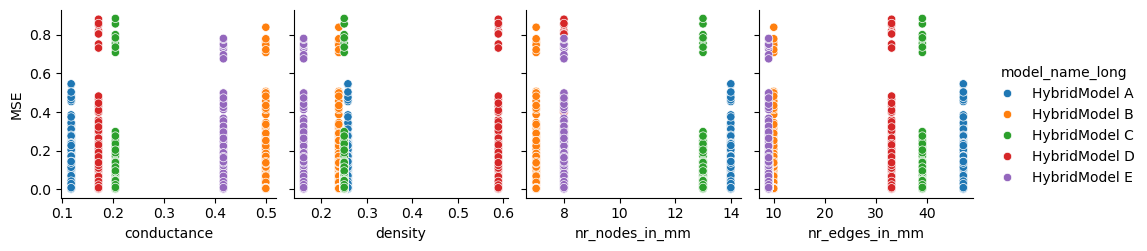

In [29]:
g = sns.pairplot(mse_df_long_model_name, hue='model_name_long', y_vars=DfColumnNames.MSE_COL, x_vars=['conductance', 'density', 'nr_nodes_in_mm', 'nr_edges_in_mm'])
for ax in g.axes.flat:
    for collection in ax.collections:
        collection.set_rasterized(True)
g.savefig("comparing_mm_pairplot_mse_only.pdf", dpi=600, bbox_inches='tight')

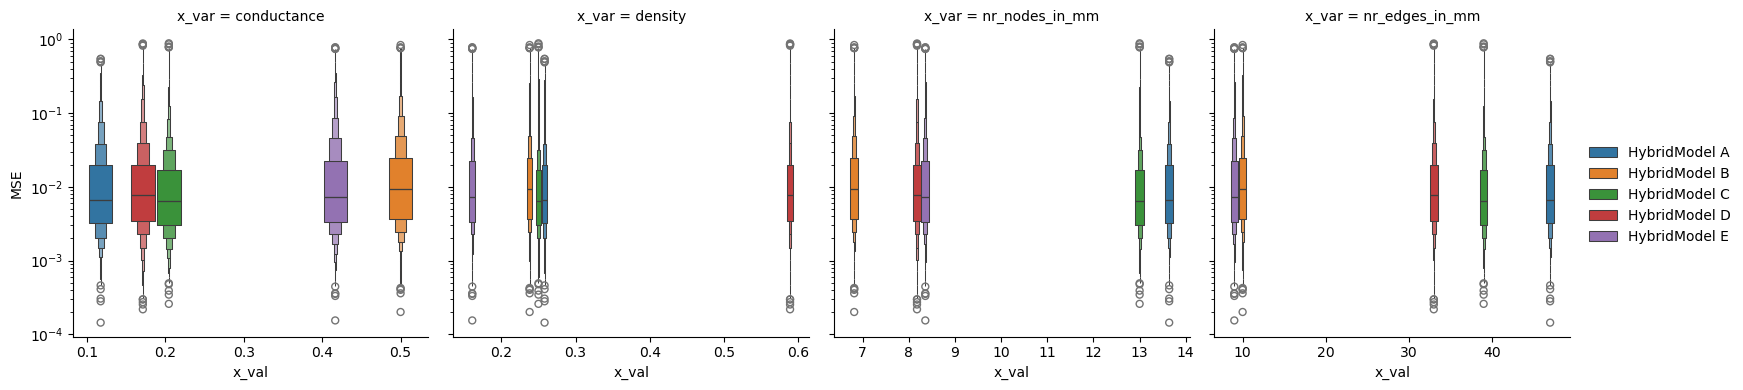

In [30]:
x_vars = ['conductance', 'density', 'nr_nodes_in_mm', 'nr_edges_in_mm']

df_melted = mse_df_long_model_name.melt(
    id_vars=[DfColumnNames.MSE_COL, 'model_name_long'],
    value_vars=x_vars,
    var_name='x_var',
    value_name='x_val'
)

g = sns.FacetGrid(df_melted, col='x_var', sharey=True, height=4, sharex=False)
g.map_dataframe(sns.boxenplot, x='x_val', y=DfColumnNames.MSE_COL, hue='model_name_long', native_scale=True, palette='tab10', log_scale=(False, True), width=.9)
g.add_legend()
g.savefig("comparing_mm_boxenplot_log.pdf", dpi=600, bbox_inches='tight')

In [36]:
print(mse_df_long_model_name)

      model_name_long                                     modelled_genes  \
0       HybridModel A  ['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...   
1       HybridModel A  ['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...   
2       HybridModel A  ['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...   
3       HybridModel A  ['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...   
4       HybridModel A  ['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...   
...               ...                                                ...   
12495   HybridModel E  ['Node_30', 'Node_39', 'Node_10', 'Node_22', '...   
12496   HybridModel E  ['Node_30', 'Node_39', 'Node_10', 'Node_22', '...   
12497   HybridModel E  ['Node_30', 'Node_39', 'Node_10', 'Node_22', '...   
12498   HybridModel E  ['Node_30', 'Node_39', 'Node_10', 'Node_22', '...   
12499   HybridModel E  ['Node_30', 'Node_39', 'Node_10', 'Node_22', '...   

       nr_nodes_in_mm  nr_edges_in_mm  conductance   density    gene  \
0              

In [59]:
smaller_df = mse_df_long_model_name.groupby('model_name_long')[['conductance', 'density', 'nr_nodes_in_mm', 'nr_edges_in_mm', 'MSE']].mean()

In [60]:
smaller_df

,conductance,density,nr_nodes_in_mm,nr_edges_in_mm,MSE
model_name_long,,,,,
HybridModel A,0.117647,0.258242,14.0,47.0,0.022726
HybridModel B,0.500000,0.238095,7.0,10.0,0.028341
HybridModel C,0.204545,0.250000,13.0,39.0,0.018533
HybridModel D,0.171429,0.589286,8.0,33.0,0.025292
HybridModel E,0.416667,0.160714,8.0,9.0,0.026859


                mean_drop        sd
nr_edges_in_mm   0.336384  0.211453
nr_nodes_in_mm   0.230484  0.133663
conductance      0.156004  0.091453
density          0.042711  0.023019


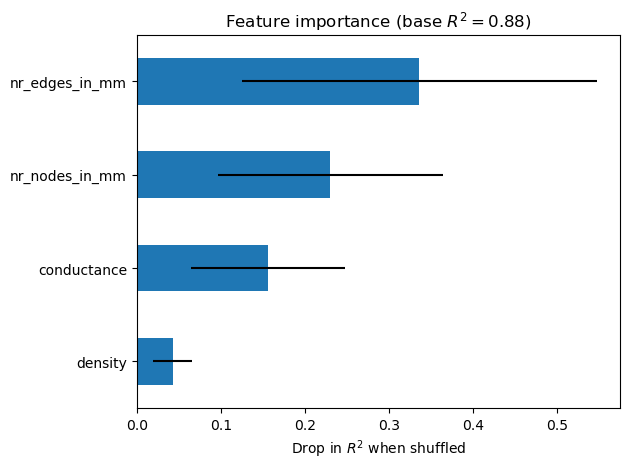

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

predictors = ['conductance', 'density', 'nr_nodes_in_mm', 'nr_edges_in_mm']
target = "MSE"

X, y = smaller_df[predictors], smaller_df[target]
model = RandomForestRegressor(n_estimators=500, random_state=174, n_jobs=-1)
model.fit(X, y)

r2 = model.score(X, y)
perm = permutation_importance(model, X, y, n_repeats=30,
                              random_state=174, n_jobs=-1)

imp = (pd.DataFrame({"mean_drop": perm.importances_mean,
                     "sd": perm.importances_std}, index=predictors)
       .sort_values("mean_drop", ascending=False))
print(imp)
ax = imp["mean_drop"].plot.barh(xerr=imp["sd"])
ax.invert_yaxis()
ax.set_xlabel("Drop in $R^2$ when shuffled")
ax.set_title(f"Feature importance (base $R^2= {r2:.2f}$)")
plt.tight_layout()
plt.savefig('random_forest_topology.pdf')